### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [195]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [196]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [197]:
len(df)

396936

In [198]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1']


In [199]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,32.9796,0,C1,C
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,32.9760,0,C1,C
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,32.9724,0,C1,C
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,32.9652,0,C1,C


In [200]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [201]:
# This code makes row windows of the data, with a given window size and stride. It returns the X and y values for each window.

# def make_row_windows(run_df, win=100, stride=20):
#     run_df = run_df.sort_values("Timer(ms)")
#     X = run_df[feature_cols].to_numpy(np.float32)
#     y = run_df["Frostbumps"].to_numpy()

#     X_clips, y_clips = [], []
#     for start in range(0, len(X) - win + 1, stride):
#         end = start + win
#         X_clips.append(X[start:end])
#         y_clips.append(y[start:end].max())

#     return np.array(X_clips), np.array(y_clips)

In [202]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [203]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=600, stride=400)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [204]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B2", "B3", "B4", "C1"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 141 windows, 30.5% positive
A2: 188 windows, 26.6% positive
A3: 286 windows, 22.4% positive
B1: 15 windows, 73.3% positive
B2: 18 windows, 55.6% positive
B3: 22 windows, 54.5% positive
B4: 44 windows, 38.6% positive
C1: 270 windows, 8.1% positive


In [205]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A2", "B1", "B3", "B2", "A3"])
Xva, yva = get_clips(["A1", "B4"])
Xte, yte = get_clips(["C1"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(529, 600, 9) (185, 600, 9) (270, 600, 9)
0.277882797731569 0.32432432432432434 0.08148148148148149


In [206]:
for run in sorted(df["run_id"].unique()):
    run_df = df[df["run_id"] == run]

    print(
        run,
        "Rows:", len(run_df),
        "Start:", run_df["Timer(ms)"].min(),
        "End:", run_df["Timer(ms)"].max()
    )

A1 Rows: 56873 Start: 45493158.5 End: 45635338.5
A2 Rows: 75465 Start: 45913936.5 End: 46102597.4
A3 Rows: 114684 Start: 46346098.5 End: 46632806.0
B1 Rows: 6426 Start: 41152199.0 End: 41168261.5
B2 Rows: 7665 Start: 41291444.0 End: 41310604.0
B3 Rows: 9222 Start: 41411763.5 End: 41434816.0
B4 Rows: 18128 Start: 41518221.1 End: 41563788.5
C1 Rows: 108473 Start: 48120264.5 End: 48391444.5


In [207]:
print(df.groupby("road_id")[feature_cols].mean().T)

road_id             A          B          C
AccX         0.514394   0.046757   0.469171
AccY         0.328778   0.117715   0.038334
AccZ         9.816107   9.864215   9.821380
GyrX        -0.004915  -0.005997  -0.005255
GyrY         0.001008  -0.000010   0.000361
GyrZ        -0.002868  -0.004975  -0.002991
Pitch(deg)  -2.897970  -1.459457  -2.688206
Roll(deg)    1.750745  -1.701137   0.098482
Speed_kmh   53.839395  54.079721  41.239983


In [208]:
print(df.groupby("road_id")[feature_cols].std().T)

road_id             A          B         C
AccX         0.599047   0.887262  0.437965
AccY         0.556965   0.451590  0.498254
AccZ         1.194532   1.248911  0.804497
GyrX         0.036716   0.038491  0.031170
GyrY         0.049027   0.058670  0.056177
GyrZ         0.012287   0.009165  0.022747
Pitch(deg)   0.997085   7.439116  1.182237
Roll(deg)    0.812936   6.912375  1.545871
Speed_kmh   15.716943  13.851292  1.643549


In [209]:
print(feature_cols)

['AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Pitch(deg)', 'Roll(deg)', 'Speed_kmh']


In [210]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

n_features = Xtr.shape[2]

Xtr_scaled = scaler.fit_transform(
    Xtr.reshape(-1, n_features)
).reshape(Xtr.shape)

Xva_scaled = scaler.transform(
    Xva.reshape(-1, n_features)
).reshape(Xva.shape)

Xte_scaled = scaler.transform(
    Xte.reshape(-1, n_features)
).reshape(Xte.shape)

In [211]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(16, 7, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 5, padding="same", activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)

history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32,
        #   class_weight={0: 1.0, 1: float(w)},
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=10, restore_best_weights=True)])



Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 1.4178 - pr_auc: 0.2579 - val_loss: 0.8758 - val_pr_auc: 0.3488
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9648 - pr_auc: 0.2628 - val_loss: 0.7403 - val_pr_auc: 0.2897
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7591 - pr_auc: 0.2921 - val_loss: 0.6828 - val_pr_auc: 0.2974
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7244 - pr_auc: 0.2780 - val_loss: 0.7690 - val_pr_auc: 0.3658
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6295 - pr_auc: 0.3249 - val_loss: 0.7138 - val_pr_auc: 0.4114
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5863 - pr_auc: 0.3744 - val_loss: 0.8182 - val_pr_auc: 0.4160
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5849 - pr_auc: 0.3963 - val_loss: 0.7354 - val_pr_auc: 0.4137
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5792 - pr_auc: 0.4274 - val_loss: 0.8248 - val_pr_auc: 0.4600
Epoch 9/

In [212]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_14 (Conv1D)              │ (None, 600, 16)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 300, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 300, 32)        │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_7          │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,485 (48.77 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,324 (32.52 KB)

In [213]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
PR-AUC:  0.4255
ROC-AUC: 0.7812


<Axes: >

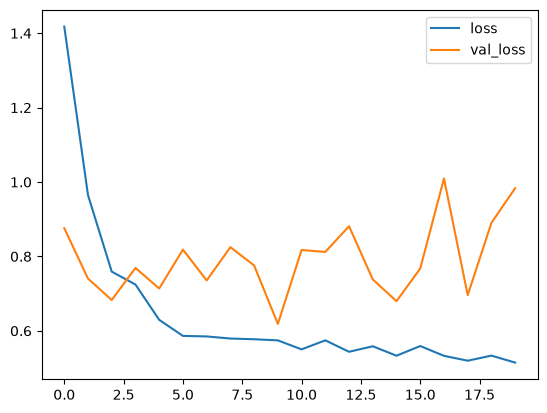

In [214]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [215]:
print("Training:", len(ytr), ytr.mean())
print("Validation:", len(yva), yva.mean())
print("Test:", len(yte), yte.mean())

Training: 529 0.277882797731569
Validation: 185 0.32432432432432434
Test: 270 0.08148148148148149


In [216]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[0.3639073967933655, 0.421101838350296]

Train data evaluation:
[0.5394213199615479, 0.5616751313209534]


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


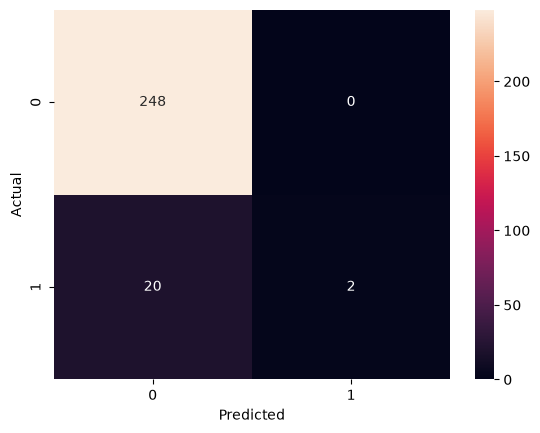

In [217]:
test_predictions = model.predict(Xte).ravel()

test_predictions = (test_predictions >= 0.50).astype(int)


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [218]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(Xte).ravel() >= 0.5).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
[[248   0]
 [ 20   2]]
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       248
           1       1.00      0.09      0.17        22

    accuracy                           0.93       270
   macro avg       0.96      0.55      0.56       270
weighted avg       0.93      0.93      0.90       270


Model overall accuracy: 92.59%


In [219]:
y_prob = model.predict(Xte).ravel()

print("Minimum:", y_prob.min())
print("Maximum:", y_prob.max())
print("Mean:", y_prob.mean())

y_pred = (y_prob >= 0.5).astype(int)

print("Predicted classes:")
print(np.unique(y_pred, return_counts=True))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Minimum: 0.19403845
Maximum: 0.7294463
Mean: 0.2637425
Predicted classes:
(array([0, 1]), array([268,   2]))


In [220]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= 0.5))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Actual frost bumps: 22
Predicted frost bumps: 2

Probabilities for actual frost bumps:
[0.4824823  0.4686905  0.22439769 0.23366223 0.2556398  0.26346937
 0.25786233 0.25718617 0.28333208 0.30957192 0.28744927 0.32798445
 0.34001455 0.26392573 0.44337314 0.41856566 0.30206203 0.2576125
 0.7294463  0.58349085 0.31421217 0.327545  ]


In [221]:
# runs = ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]

# test_run = "A1"
# val_run = "A2"
# train_runs = [r for r in runs if r not in (test_run, val_run)]

# print(train_runs)

In [222]:
# def build_model(input_shape):
#     model = keras.Sequential([
#         layers.Input(shape=input_shape),
#         layers.Conv1D(8, 7, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(16, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.3),
#         layers.Dense(16, activation="relu"),
#         layers.Dense(1, activation="sigmoid"),
#     ])
#     model.compile(optimizer="adam", loss="binary_crossentropy")
#     return model

In [223]:
# scores = {}

# for i, test_run in enumerate(runs):
#     val_run = runs[(i + 1) % len(runs)]
#     train_runs = [r for r in runs if r not in (test_run, val_run)]

#     Xtr, ytr = get_clips(train_runs)
#     Xva, yva = get_clips([val_run])
#     Xte, yte = get_clips([test_run])

#     n_features = Xtr.shape[-1]
#     scaler = StandardScaler().fit(Xtr.reshape(-1, n_features))
#     Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
#     Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
#     Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

#     keras.backend.clear_session()
#     model = build_model(Xtr.shape[1:])

#     model.fit(
#         Xtr, ytr,
#         validation_data=(Xva, yva),
#         epochs=30,
#         batch_size=32,
#         class_weight={0: 1.0, 1: 3.0},
#         verbose=0,
#         callbacks=[keras.callbacks.EarlyStopping(
#             monitor="val_loss", patience=5, restore_best_weights=True)],
#     )

#     probs = model.predict(Xte, verbose=0).ravel()
#     scores[test_run] = average_precision_score(yte, probs)
#     print(test_run, "score:", round(scores[test_run], 2),
#           "| random guess:", round(yte.mean(), 2))

# print("mean:", sum(scores.values()) / len(scores))